X shape: torch.Size([100, 2]) y shape: torch.Size([100, 1])
epoch   0: loss = 3173.5
epoch  50: loss = 219.5
epoch 100: loss = 106.0
epoch 150: loss = 76.3
epoch 200: loss = 62.9
epoch 250: loss = 54.7


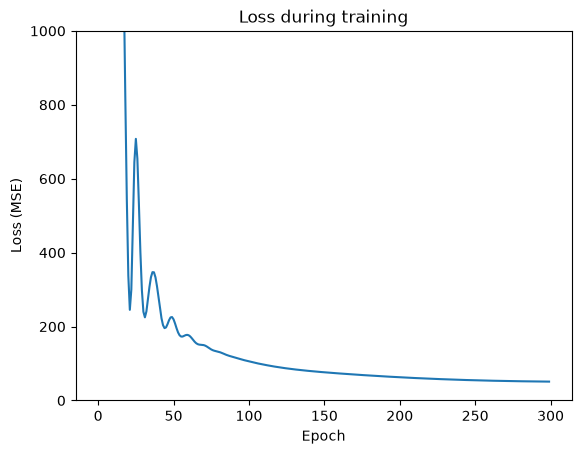

3 study hours, 2 phone hours - 61.18 marks


In [ ]:

import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_csv("students_100.csv")

X = torch.tensor(
    students[["study_hours", "phone_hours"]].values,
    dtype=torch.float32
)

y = torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32
)

print("X shape:", X.shape, "y shape:", y.shape)

torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

losses = []

for epoch in range(300):
    guess = model(X)
    loss = loss_fn(guess, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if epoch % 50 == 0:
        print(f"epoch {epoch:3}: loss = {loss.item():.1f}")

plt.plot(losses)
plt.ylim(0, 1000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

with torch.no_grad():
    new_student = torch.tensor([[3, 2]], dtype=torch.float32)
    prediction = model(new_student)

    print("3 study hours, 2 phone hours -",round(prediction.item(), 2), "marks")




